
# Comparative and Absolute Probability Phrase Dataset (CAP): Understanding Probability Language

## Research objective

This project investigates how people interpret probability
expressions and whether their numerical probability estimates
are consistent with their comparative judgments.

The analysis combines exploratory data analysis, statistical
modeling, uncertainty quantification, and model validation.

## Research questions

1. How do people interpret different probability phrases?
2. How much disagreement exists between respondents?
3. Are numerical probability estimates consistent with
   pairwise comparisons?
4. Can respondent characteristics explain differences
   in probability interpretation?
5. How does presentation order influence judgments?
6. Which statistical models best describe these patterns?

## Data source

TidyTuesday — March 10, 2026

Original dataset: CAPphrase

All results will be interpreted in the context of the
study's sampling and experimental design.


In [3]:

from pathlib import Path

import pandas as pd
import numpy as np

# Project paths
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "likely" /"tidytuesday" 

# Load local CSV files
absolute = pd.read_csv(
    DATA_DIR / "absolute_judgements.csv"
)

pairwise = pd.read_csv(
    DATA_DIR / "pairwise_comparisons.csv"
)

metadata = pd.read_csv(
    DATA_DIR / "respondent_metadata.csv"
)

# Inspect dataset dimensions
for name, df in {
    "absolute": absolute,
    "pairwise": pairwise,
    "metadata": metadata,
}.items():
    print(f"{name}: {df.shape}")


absolute: (98306, 4)
pairwise: (51740, 5)
metadata: (5174, 6)


In [4]:
for name, df in {
    "absolute": absolute,
    "pairwise": pairwise,
    "metadata": metadata,
}.items():

    print(f"\n{'=' * 60}")
    print(name.upper())
    print(f"{'=' * 60}")

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nFirst five rows:")
    display(df.head())

    print("\nMissing values:")
    display(df.isna().sum())

    print("\nDuplicate rows:")
    print(df.duplicated().sum())



ABSOLUTE

Columns:
['response_id', 'term', 'probability', 'order']

Data types:
response_id    int64
term             str
probability    int64
order          int64
dtype: object

First five rows:


,response_id,term,probability,order
0,5177,Little Chance,20,1
1,5177,Almost No Chance,9,2
2,5177,Remote Chance,18,3
3,5177,May Happen,44,4
4,5177,Chances are Slight,27,5



Missing values:


response_id    0
term           0
probability    0
order          0
dtype: int64


Duplicate rows:
0

PAIRWISE

Columns:
['response_id', 'pair_id', 'term1', 'term2', 'selected']

Data types:
response_id    int64
pair_id        int64
term1            str
term2            str
selected         str
dtype: object

First five rows:


,response_id,pair_id,term1,term2,selected
0,5177,1,Very Good Chance,Remote Chance,Very Good Chance
1,5177,2,Almost No Chance,Realistic Possibility,Realistic Possibility
2,5177,3,Could Happen,Little Chance,Could Happen
3,5177,4,Chances are Slight,Improbable,Chances are Slight
4,5177,5,Probable,Unlikely,Probable


... (3 outputs left out)

,response_id,timestamp,age_band,english_background,education_level,country_of_residence
0,5177,2026-02,45-54,English is my first language,Bachelor,United States
1,5176,2026-02,25-34,English is my first language,Postgraduate,United States
2,5175,2026-02,NaN,NaN,NaN,NaN
3,5174,2026-02,25-34,English is my first language,Bachelor,Myanmar (Burma)
4,5173,2026-02,NaN,NaN,NaN,NaN



Missing values:


response_id               0
timestamp                 0
age_band                437
english_background      421
education_level         663
country_of_residence    720
dtype: int64


Duplicate rows:
0


In [5]:
import pandas as pd
import numpy as np

# 1. Basic dimensions
print("Absolute judgments:", absolute.shape)
print("Pairwise comparisons:", pairwise.shape)
print("Respondent metadata:", metadata.shape)

# 2. Unique respondents
print("\nUnique respondents")
print("Absolute:", absolute["response_id"].nunique())
print("Pairwise:", pairwise["response_id"].nunique())
print("Metadata:", metadata["response_id"].nunique())

# 3. Expected number of observations per respondent
print("\nAbsolute judgments per respondent:")
print(absolute.groupby("response_id").size().value_counts().sort_index())

print("\nPairwise comparisons per respondent:")
print(pairwise.groupby("response_id").size().value_counts().sort_index())

# 4. Duplicate respondent-term and respondent-pair combinations
print("\nDuplicate respondent-term records:",
      absolute.duplicated(["response_id", "term"]).sum())

print("Duplicate respondent-pair records:",
      pairwise.duplicated(["response_id", "pair_id"]).sum())

# 5. Probability range
print("\nProbability range:")
print(absolute["probability"].agg(["min", "max"]))

# 6. Is selected one of the two displayed phrases?
valid_selection = (
    pairwise["selected"].eq(pairwise["term1"])
    | pairwise["selected"].eq(pairwise["term2"])
)

print("\nSelections outside term1/term2:", (~valid_selection).sum())

# 7. Pair IDs per respondent
print("\nPair IDs observed:")
print(sorted(pairwise["pair_id"].dropna().unique()))

Absolute judgments: (98306, 4)
Pairwise comparisons: (51740, 5)
Respondent metadata: (5174, 6)

Unique respondents
Absolute: 5174
Pairwise: 5174
Metadata: 5174

Absolute judgments per respondent:
19    5174
Name: count, dtype: int64

Pairwise comparisons per respondent:
10    5174
Name: count, dtype: int64

Duplicate respondent-term records: 0
Duplicate respondent-pair records: 0

Probability range:
min      0
max    100
Name: probability, dtype: int64

Selections outside term1/term2: 0

Pair IDs observed:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


In [6]:
first = (
    pairwise[pairwise["pair_id"] == 1]
    [["response_id", "term1", "term2", "selected"]]
    .rename(columns={
        "term1": "term1_first",
        "term2": "term2_first",
        "selected": "selected_first"
    })
)

last = (
    pairwise[pairwise["pair_id"] == 10]
    [["response_id", "term1", "term2", "selected"]]
    .rename(columns={
        "term1": "term1_last",
        "term2": "term2_last",
        "selected": "selected_last"
    })
)

repeat = first.merge(last, on="response_id")

repeat["same_pair"] = repeat.apply(
    lambda r: {r["term1_first"], r["term2_first"]}
    == {r["term1_last"], r["term2_last"]},
    axis=1
)

repeat["same_choice"] = (
    repeat["selected_first"] == repeat["selected_last"]
)

print("Same pair:", repeat["same_pair"].sum(), "/", len(repeat))

print(
    "Choice consistency:",
    repeat.loc[repeat["same_pair"], "same_choice"].mean()
)

Same pair: 5174 / 5174
Choice consistency: 0.9663703131039815


In [7]:
phrase_summary = (
    absolute.groupby("term")
    .agg(
        mean_probability=("probability", "mean"),
        median_probability=("probability", "median"),
        std_probability=("probability", "std"),
        min_probability=("probability", "min"),
        max_probability=("probability", "max"),
        respondents=("response_id", "nunique")
    )
    .sort_values("median_probability")
)

display(phrase_summary.round(2))

,mean_probability,median_probability,std_probability,min_probability,max_probability,respondents
term,,,,,,
Almost No Chance,3.91,2.0,6.04,0,100,5174
Remote Chance,8.72,5.0,9.93,0,100,5174
Highly Unlikely,9.21,5.0,12.41,0,100,5174
Chances are Slight,13.00,10.0,10.21,0,100,5174
Improbable,13.44,10.0,11.60,0,100,5174
Little Chance,11.68,10.0,8.08,0,99,5174
Unlikely,19.01,20.0,11.30,0,100,5174
Could Happen,39.66,40.0,18.23,0,95,5174
May Happen,41.88,40.0,17.02,0,100,5174


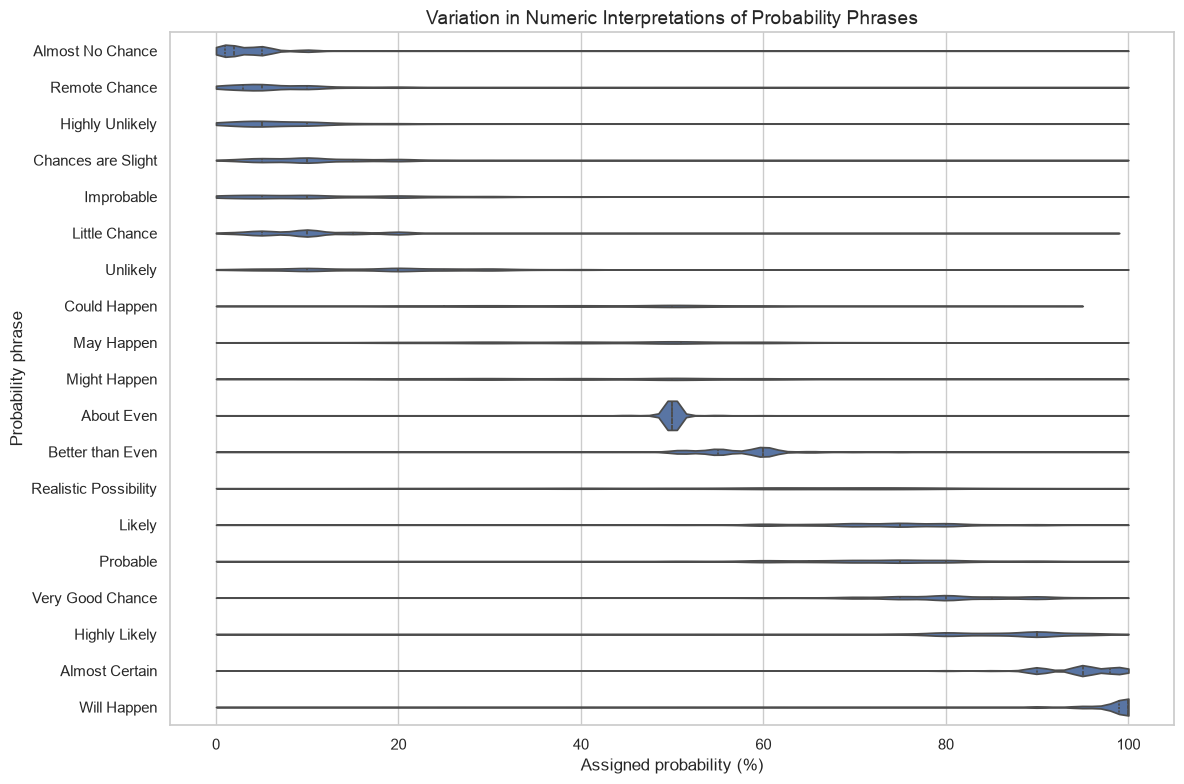

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

order = phrase_summary.index.tolist()

fig, ax = plt.subplots(figsize=(12, 8))

sns.violinplot(
    data=absolute,
    x="probability",
    y="term",
    order=order,
    inner="quartile",
    cut=0,
    ax=ax
)

ax.set_title(
    "Variation in Numeric Interpretations of Probability Phrases",
    fontsize=14
)
ax.set_xlabel("Assigned probability (%)")
ax.set_ylabel("Probability phrase")

plt.tight_layout()
plt.show()

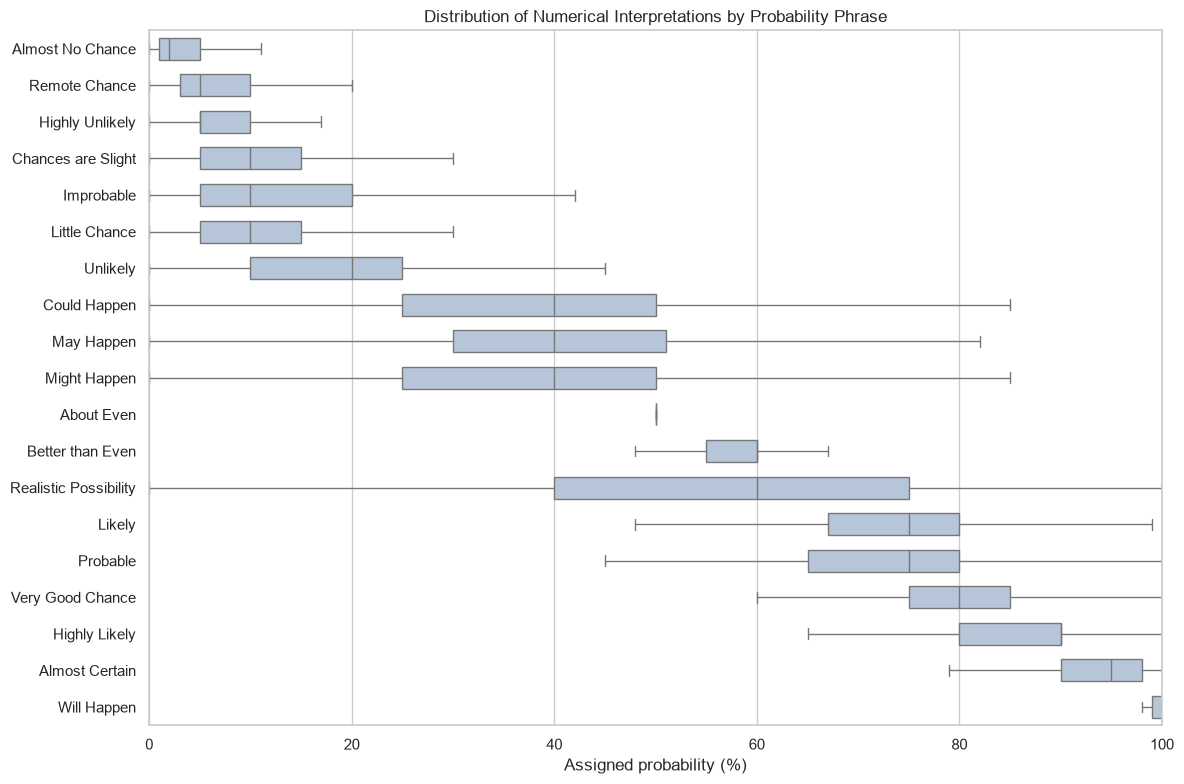

In [12]:
term_order = phrase_summary.index.tolist()
fig, ax = plt.subplots(figsize=(12, 8))

sns.boxplot(
    data=absolute,
    x="probability",
    y="term",
    order=term_order,
    showfliers=False,
    color="lightsteelblue",
    width=0.6,
    ax=ax
)

ax.set_xlim(0, 100)
ax.set_xlabel("Assigned probability (%)")
ax.set_ylabel("")
ax.set_title("Distribution of Numerical Interpretations by Probability Phrase")

plt.tight_layout()
plt.show()